# MoodMate: Six-Class Emotion Classification

MoodMate is a **collaborative NLP and machine learning project** exploring the classification of short text into six emotions: sadness, joy, love, anger, fear, and surprise. This notebook compares Logistic Regression, Multinomial Naive Bayes, and Random Forest using TF-IDF features.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

from pathlib import Path
import pandas as pd

# Place training.csv, validation.csv, and test.csv in ./data/ (preferred)
# or beside this notebook. No Google Drive mount or upload is required.
data_dir = Path("data") if Path("data/training.csv").is_file() else Path(".")
required_files = ("training.csv", "validation.csv", "test.csv")
missing = [name for name in required_files if not (data_dir / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {data_dir.resolve()}. "
        "Place the original CSV files in a data/ folder or beside this notebook."
    )

train_df = pd.read_csv(data_dir / "training.csv")
val_df = pd.read_csv(data_dir / "validation.csv")
test_df = pd.read_csv(data_dir / "test.csv")
for split_name, frame in (("training", train_df), ("validation", val_df), ("test", test_df)):
    if not {"text", "label"}.issubset(frame.columns):
        raise ValueError(f"{split_name}.csv must contain 'text' and 'label' columns")
    if frame[["text", "label"]].isna().any().any():
        raise ValueError(f"{split_name}.csv contains missing text or labels")

LABEL_NAMES = {0: "sadness", 1: "joy", 2: "love", 3: "anger", 4: "fear", 5: "surprise"}

## Exploratory analysis

Examine the distribution of emotion labels and message lengths in the **training split**. Numeric labels follow the mapping defined above.

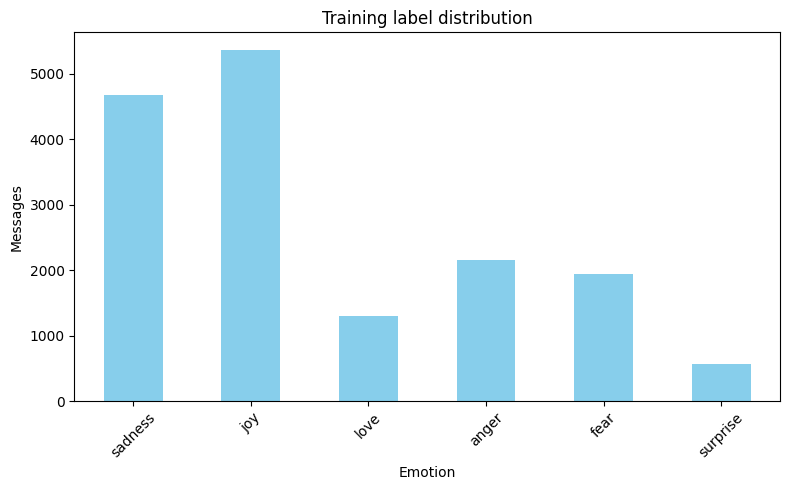

In [ ]:
label_counts = train_df["label"].value_counts().sort_index()
ax = label_counts.rename(index=LABEL_NAMES).plot(kind="bar", figsize=(8, 5), color="skyblue")
ax.set(title="Training label distribution", xlabel="Emotion", ylabel="Messages")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

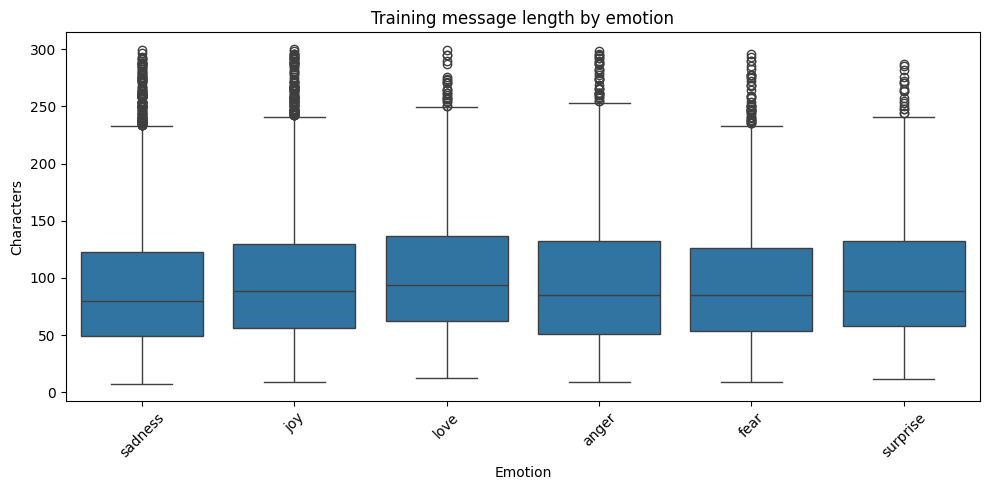

In [ ]:
train_lengths = train_df.assign(text_length=train_df["text"].str.len())
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_lengths, x="label", y="text_length", order=list(LABEL_NAMES))
plt.xticks(list(LABEL_NAMES), list(LABEL_NAMES.values()), rotation=45)
plt.title("Training message length by emotion")
plt.xlabel("Emotion")
plt.ylabel("Characters")
plt.tight_layout()
plt.show()

## Text features

TF-IDF represents each message as a sparse vector of weighted terms. The vectorizer is **fitted only on training text**, then applied unchanged to validation text to avoid vocabulary leakage. English stop-word removal is retained from the original experiment; it can discard useful context, including negations, and was not separately tuned.

In [ ]:
train_texts, val_texts = train_df["text"], val_df["text"]
y_train, y_val = train_df["label"], val_df["label"]
vectorizer = TfidfVectorizer(stop_words="english")
X_train = vectorizer.fit_transform(train_texts)
X_val = vectorizer.transform(val_texts)
print(f"Training matrix shape: {X_train.shape}")
print(f"Validation matrix shape: {X_val.shape}")
print("Sample vocabulary:", vectorizer.get_feature_names_out()[:10])

Training matrix shape: (16000, 14894)
Validation matrix shape: (2000, 14894)
Sample vocabulary: ['aa' 'aaaaaaand' 'aaaaand' 'aaaand' 'aac' 'aahhh' 'aaron' 'ab' 'abandon'
 'abandoned']


The original run produced a 16,000 × 14,894 training matrix and a 2,000 × 14,894 validation matrix. Each row represents a message and each column a term learned from training data.

## Logistic Regression

Train a linear classifier on TF-IDF features and report per-class precision, recall, and F1-score on the validation split.

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_val)
print("Accuracy:", accuracy_score(y_val, y_pred))
print("Detailed scores:\n", classification_report(y_val, y_pred))

Accuracy: 0.8745
Detailed scores:
               precision    recall  f1-score   support

           0       0.88      0.94      0.91       550
           1       0.86      0.95      0.90       704
           2       0.90      0.70      0.78       178
           3       0.90      0.85      0.88       275
           4       0.87      0.74      0.80       212
           5       0.85      0.65      0.74        81

    accuracy                           0.87      2000
   macro avg       0.88      0.80      0.83      2000
weighted avg       0.88      0.87      0.87      2000



**Original validation accuracy: 87.45%.** The classification report shows lower recall for less frequent classes, especially surprise. Precision measures the correctness of predicted labels, recall measures coverage of true labels, and F1 balances the two.

## Multinomial Naive Bayes

Compare a probabilistic text-classification baseline using the same TF-IDF features. The original model predicted **no validation examples of class 5 (surprise)**, making its precision mathematically undefined. `zero_division=0` explicitly reports this as 0; it does not fix the underlying failure. Inspect class-level recall rather than accuracy alone.

In [ ]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_val)
print("Naive Bayes Accuracy:", accuracy_score(y_val, y_pred_nb))
print("Naive Bayes Detailed Scores:\n", classification_report(y_val, y_pred_nb, zero_division=0))

Naive Bayes Accuracy: 0.681
Naive Bayes Detailed Scores:
               precision    recall  f1-score   support

           0       0.66      0.93      0.77       550
           1       0.65      0.97      0.78       704
           2       1.00      0.07      0.13       178
           3       0.97      0.34      0.50       275
           4       0.95      0.28      0.44       212
           5       0.00      0.00      0.00        81

    accuracy                           0.68      2000
   macro avg       0.71      0.43      0.44      2000
weighted avg       0.73      0.68      0.61      2000



**Original validation accuracy: 68.10%.** The original classification report records zero recall for surprise (class 5), and much lower recall for several minority classes. The historical warning messages are omitted because the reporting behavior is now explicit.

## Random Forest

Fit the original 100-tree Random Forest using the same training-only TF-IDF representation.

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_val)
print("Random Forest Accuracy:", accuracy_score(y_val, y_pred_rf))
print("Random Forest Detailed Scores:\n", classification_report(y_val, y_pred_rf))

Random Forest Accuracy: 0.8985
Random Forest Detailed Scores:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92       550
           1       0.90      0.93      0.91       704
           2       0.86      0.80      0.83       178
           3       0.93      0.87      0.90       275
           4       0.85      0.88      0.87       212
           5       0.86      0.79      0.83        81

    accuracy                           0.90      2000
   macro avg       0.89      0.87      0.88      2000
weighted avg       0.90      0.90      0.90      2000



## Interpretation and limitations

**Original validation accuracies:** Logistic Regression **87.45%**, Naive Bayes **68.10%**, and Random Forest **89.85%**. Random Forest performed best on this validation split. These are historical saved outputs, not fresh verification.

- The label distribution is uneven; accuracy should be considered alongside per-class precision, recall, and F1.
- The companion `randomForest.ipynb` explores CountVectorizer and TF-IDF Random Forest variants with a separate held-out test split.